# 06 – Where should charging investment go?

**Business question 4.** Which provinces should be prioritised for public charging investment?

Notebooks 04 and 05 showed that no single measure is enough:
- Eastern provinces look well served per car only because they have few cars.
- Richer provinces have more charging per person, but also many more car buyers.

So the priority score combines **three indicators**, each pointing to a different reason to invest:

| Indicator | What it measures | Why it matters |
| --- | --- | --- |
| Public stations per 10,000 cars (reversed: fewer = higher priority) | today's gap | pressure on the existing network |
| Households in buildings without a car park (BKNA 2021) | how many households are unlikely to charge at home | these drivers depend on public charging |
| New cars per 1,000 people, January–September 2026 | future electric car demand | electric cars are 19% of new cars (notebook 03), so they are bought where new cars are bought |

**Why not the growth of the car fleet?** It was tested, but the fastest-growing fleets are in eastern provinces with very few cars (a small base grows fast in percent). New car registrations per person follow income closely (Spearman 0.74), as electric car sales do.

**Scoring method (simple and transparent):**
1. Each indicator is converted to a **percentile rank** from 0 to 1 (0.9 = higher priority than 90% of provinces). Ranks are used instead of raw values so one extreme province (e.g. Hakkari with 28 stations per 10,000 cars) cannot dominate.
2. The **priority score** is the simple average of the three ranks, with equal weights, because there is no evidence to say one matters more.

This is the same as `PERCENTRANK` and `AVERAGE` in Excel.

**Scope:** all 81 provinces. The analysis is about charging where people live and shop; charging along motorways is a different question and is not covered.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. Build the three indicators

In [2]:
provinces = pd.read_csv(PROCESSED + "province_charging_gap.csv")
groups = pd.read_csv(PROCESSED + "province_development_groups.csv")
provinces = provinces.merge(groups[["province_code", "hdi_group"]], on="province_code", validate="1:1")
provinces["new_cars_per_1000_people"] = provinces["new_cars_2026_jan_sep"] / provinces["population_2025"] * 1000

INDICATORS = {
    # column: (label, True if a higher value means higher priority)
    "stations_per_10k_cars": ("Charging gap today", False),
    "no_parking_share_2021": ("No car park at home", True),
    "new_cars_per_1000_people": ("New car demand", True),
}
for col, (label, higher_is_priority) in INDICATORS.items():
    provinces["rank_" + col] = provinces[col].rank(pct=True, ascending=higher_is_priority)

provinces[list(INDICATORS)].describe().round(2)

,stations_per_10k_cars,no_parking_share_2021,new_cars_per_1000_people
count,81.00,81.00,81.00
mean,9.06,0.62,4.47
std,4.48,0.13,2.46
min,2.44,0.20,0.95
25%,5.77,0.53,3.02
50%,7.92,0.63,3.93
75%,11.88,0.70,5.30
max,28.31,0.85,16.82


In [3]:
# How the indicators relate to each other (Spearman = correlation of the ranks)
provinces[list(INDICATORS)].rank().corr().round(2)

,stations_per_10k_cars,no_parking_share_2021,new_cars_per_1000_people
stations_per_10k_cars,1.00,0.28,-0.15
no_parking_share_2021,0.28,1.00,-0.41
new_cars_per_1000_people,-0.15,-0.41,1.00


In the typical province, 63% of households live in a building without a car park, and 3.9 new cars per 1,000 people were registered in January–September 2026 (Istanbul 16.8, Ankara 12.1).

The indicators pull in different directions: provinces with many new cars have **more** car parks (Spearman −0.41) and slightly fewer stations per car. This is why one measure alone would give a one-sided picture.

**Caveat on new cars:** leasing and rental companies register cars at their head office, so Istanbul and Ankara's new car figures are inflated. Because ranks are used, this only means they rank first and second on this indicator, which they would probably do anyway.

## 2. Priority score

In [4]:
rank_cols = ["rank_" + col for col in INDICATORS]
provinces["priority_score"] = provinces[rank_cols].mean(axis=1)
# Rounded before ranking, so that provinces with exactly the same ranks share a place (floating point noise)
provinces["priority_rank"] = provinces["priority_score"].round(9).rank(ascending=False, method="min").astype(int)
provinces = provinces.sort_values("priority_rank").reset_index(drop=True)

top20 = provinces.head(20)
show = ["priority_rank", "province", "region", "priority_score", *rank_cols,
        "stations_per_10k_cars", "no_parking_share_2021", "new_cars_per_1000_people"]
top20[show].round(2)

,priority_rank,province,region,priority_score,rank_stations_per_10k_cars,rank_no_parking_share_2021,rank_new_cars_per_1000_people,stations_per_10k_cars,no_parking_share_2021,new_cars_per_1000_people
0,1,İzmir,Ege,0.80,0.88,0.58,0.95,5.00,0.66,8.73
1,2,Kırşehir,Orta Anadolu,0.76,0.89,0.88,0.51,4.98,0.78,3.93
2,3,Hatay,Akdeniz,0.72,1.00,0.53,0.64,2.44,0.65,4.59
3,4,Adıyaman,Güneydoğu Anadolu,0.72,0.96,0.78,0.41,3.67,0.70,3.75
4,5,Denizli,Ege,0.71,0.48,0.79,0.86,8.01,0.71,6.05
5,6,İstanbul,İstanbul,0.70,0.63,0.48,1.00,6.51,0.63,16.82
6,6,Manisa,Ege,0.70,0.80,0.89,0.42,5.58,0.79,3.76
7,8,Elazığ,Ortadoğu Anadolu,0.69,0.69,0.62,0.77,6.25,0.66,5.38
8,9,Erzincan,Kuzeydoğu Anadolu,0.67,0.78,0.68,0.54,5.65,0.68,3.94
9,10,Balıkesir,Batı Marmara,0.66,0.32,0.83,0.84,10.80,0.75,5.95


**Indicative size of the investment.** For each province, how many extra public stations would bring it up to the median province (7.9 stations per 10,000 cars)? This is a rough, relative guide, not a forecast: it uses today's cars, ignores future growth and counts stations, not sockets.

In [5]:
MEDIAN_PER_10K_CARS = provinces["stations_per_10k_cars"].median()
provinces["stations_to_median"] = (MEDIAN_PER_10K_CARS * provinces["cars"] / 10_000
                                   - provinces["public_stations"]).clip(lower=0).round().astype(int)
top20 = provinces.head(20)
print(f"Median province: {MEDIAN_PER_10K_CARS:.1f} stations per 10,000 cars")
print(f"Top 20 today: {top20['public_stations'].sum():,} public stations; "
      f"to reach the median: {top20['stations_to_median'].sum():,} more")
top20[["priority_rank", "province", "cars", "public_stations", "stations_to_median"]]

Median province: 7.9 stations per 10,000 cars
Top 20 today: 5,799 public stations; to reach the median: 1,629 more


,priority_rank,province,cars,public_stations,stations_to_median
0,1,İzmir,1130163,565,330
1,2,Kırşehir,50176,25,15
2,3,Hatay,290403,71,159
3,4,Adıyaman,73551,27,31
4,5,Denizli,272117,218,0
5,6,İstanbul,4210192,2742,593
6,6,Manisa,286637,160,67
7,8,Elazığ,107136,67,18
8,9,Erzincan,38907,22,9
9,10,Balıkesir,289797,313,0


In [6]:
print("Lowest 10 priority scores")
provinces.tail(10)[["priority_rank", "province", "region", "priority_score", *rank_cols]].round(2)

Lowest 10 priority scores


,priority_rank,province,region,priority_score,rank_stations_per_10k_cars,rank_no_parking_share_2021,rank_new_cars_per_1000_people
71,72,Kastamonu,Batı Karadeniz,0.35,0.58,0.15,0.32
72,73,Şırnak,Güneydoğu Anadolu,0.35,0.04,0.98,0.02
73,74,Hakkari,Ortadoğu Anadolu,0.32,0.01,0.94,0.01
74,75,Düzce,Doğu Marmara,0.31,0.25,0.10,0.59
75,76,Ardahan,Kuzeydoğu Anadolu,0.30,0.10,0.65,0.16
76,77,Van,Ortadoğu Anadolu,0.30,0.16,0.60,0.12
77,78,Bolu,Doğu Marmara,0.29,0.19,0.02,0.67
78,79,Gümüşhane,Doğu Karadeniz,0.28,0.26,0.43,0.15
79,80,Yozgat,Orta Anadolu,0.27,0.54,0.12,0.14
80,81,Çankırı,Batı Karadeniz,0.17,0.20,0.09,0.23


## 3. Charts

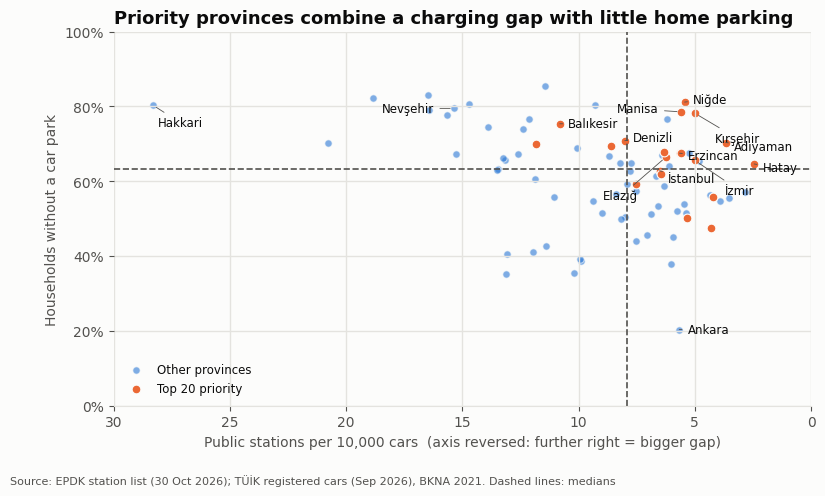

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
is_top = provinces["priority_rank"] <= 20
ax.scatter(provinces.loc[~is_top, "stations_per_10k_cars"], provinces.loc[~is_top, "no_parking_share_2021"] * 100,
           s=28, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.8, label="Other provinces")
ax.scatter(provinces.loc[is_top, "stations_per_10k_cars"], provinces.loc[is_top, "no_parking_share_2021"] * 100,
           s=40, color=ORANGE, edgecolor=SURFACE, linewidth=0.8, label="Top 20 priority")
ax.axvline(MEDIAN_PER_10K_CARS, color=TEXT_2, linewidth=1.2, linestyle="--")
ax.axhline(provinces["no_parking_share_2021"].median() * 100, color=TEXT_2, linewidth=1.2, linestyle="--")

# Name the top 10 and a few reference provinces
labels = {"İzmir": (22, -22), "Kırşehir": (14, -18), "Hatay": (6, -3), "Adıyaman": (6, -3), "Denizli": (6, 2),
          "İstanbul": (6, -6), "Manisa": (-46, 2), "Elazığ": (-45, -28), "Erzincan": (6, -2), "Balıkesir": (6, 0),
          "Niğde": (6, 2), "Ankara": (6, 0), "Hakkari": (4, -13), "Nevşehir": (-52, 0)}
for name, (dx, dy) in labels.items():
    row = provinces.loc[provinces["province"] == name].iloc[0]
    ax.annotate(name, (row["stations_per_10k_cars"], row["no_parking_share_2021"] * 100), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=TEXT, va="center",
                arrowprops={"arrowstyle": "-", "color": TEXT_2, "linewidth": 0.6, "shrinkB": 3})

ax.invert_xaxis()
ax.set_xlim(30, 0)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Public stations per 10,000 cars  (axis reversed: further right = bigger gap)")
ax.set_ylabel("Households without a car park")
ax.grid(axis="x", visible=True)
ax.set_title("Priority provinces combine a charging gap with little home parking")
ax.legend(loc="lower left", frameon=False, fontsize=8.5)
plt.subplots_adjust(bottom=0.16)
add_source(fig, "Source: EPDK station list (30 Oct 2026); TÜİK registered cars (Sep 2026), BKNA 2021. Dashed lines: medians")
fig.savefig(FIGURES + "10_priority_matrix.png", dpi=200)
plt.show()

**How to read this chart:** each dot is a province. Further right means fewer public stations per 10,000 cars (a bigger gap today; the axis is reversed); higher up means more households without a car park. The dashed lines are the medians, so the **top-right** box holds provinces above the median on both. Orange dots are the 20 highest priority scores. The third indicator (new car demand) is not on the axes, which is why some orange dots sit outside the top-right box.

**What it shows**
- **The top-right box is where most priority provinces are:** Kırşehir, Adıyaman, Manisa, Niğde, Erzincan, Hatay and Elazığ have both a clear gap and many households without a car park.
- **Big cities enter the list through demand**, not parking: İzmir and Istanbul are near the median on parking but have a gap and the most new car buyers.
- Denizli and Balıkesir are in the top 20 **without** a gap today (around or above the median stations per car): they rank high on parking and on new car demand, so they are where the gap is likely to appear next.
- **Ankara** (bottom right) has a gap but only 20% of households without a car park, the lowest in Türkiye; most of its drivers can charge at home. **Hakkari** (far left) has many stations per car and few car buyers.

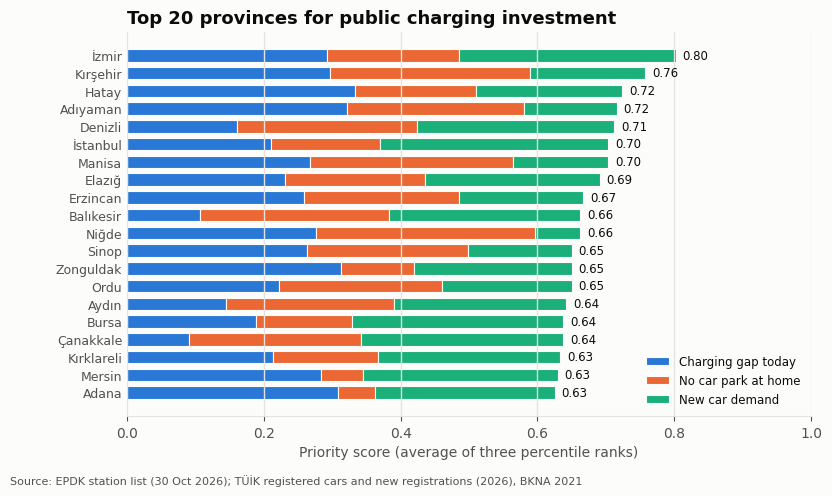

In [8]:
plot = top20.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
left = pd.Series(0.0, index=plot.index)
for col, color in zip(INDICATORS, [BLUE, ORANGE, AQUA]):
    part = plot["rank_" + col] / len(INDICATORS)
    ax.barh(plot["province"], part, left=left, color=color, height=0.7, label=INDICATORS[col][0],
            edgecolor=SURFACE, linewidth=0.8)
    left += part
for y, (score, rank) in enumerate(zip(plot["priority_score"], plot["priority_rank"])):
    ax.text(score + 0.01, y, f"{score:.2f}", va="center", fontsize=8.5, color=TEXT)

ax.set_title("Top 20 provinces for public charging investment")
ax.set_xlabel("Priority score (average of three percentile ranks)")
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0, labelsize=9)
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
plt.subplots_adjust(left=0.14, bottom=0.14)
add_source(fig, "Source: EPDK station list (30 Oct 2026); TÜİK registered cars and new registrations (2026), BKNA 2021")
fig.savefig(FIGURES + "11_top20_priority.png", dpi=200)
plt.show()

**How to read this chart:** the 20 provinces with the highest priority score. Each bar is split into the three indicators, so you can see *why* a province ranks high. A long blue part means a big gap today, orange means many households without a car park and green means many new car buyers.

**What it shows**
- **İzmir is first** (0.80): a large gap (565 stations for 1.13 million cars) and the fifth-highest new car demand (after Istanbul, Ankara, Antalya and Yalova). It also needs the most extra stations of any province after Istanbul.
- **Three types of province make up the list:**
  - **Large cities with a gap and strong demand:** İzmir, Istanbul, Bursa, Mersin, Adana.
  - **Inland Anatolian, Aegean and Black Sea provinces with a gap and little home parking:** Kırşehir, Manisa, Niğde, Erzincan, Elazığ, Sinop, Ordu.
  - **Smaller provinces with a gap and fairly strong demand:** Zonguldak, Kırklareli.
  - **The earthquake region:** Hatay and Adıyaman have the largest gaps in Türkiye.
- **Aegean and Marmara provinces with strong demand but no gap yet** (Denizli, Balıkesir, Aydın, Çanakkale) are on the list for the future rather than for today.

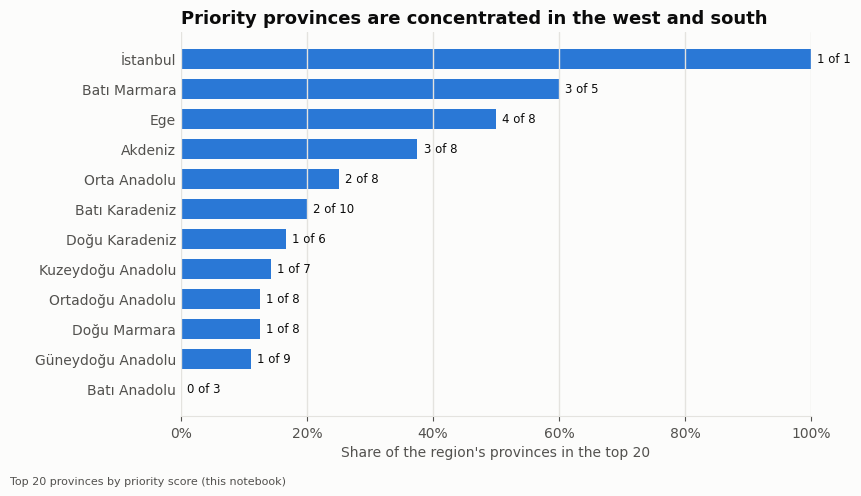

,provinces,in_top20,share_in_top20
region,,,
Batı Anadolu,3,0,0.0
Güneydoğu Anadolu,9,1,11.1
Doğu Marmara,8,1,12.5
Ortadoğu Anadolu,8,1,12.5
Kuzeydoğu Anadolu,7,1,14.3
Doğu Karadeniz,6,1,16.7
Batı Karadeniz,10,2,20.0
Orta Anadolu,8,2,25.0
Akdeniz,8,3,37.5


In [9]:
by_region = provinces.groupby("region").agg(
    provinces=("province", "size"), in_top20=("priority_rank", lambda r: (r <= 20).sum()))
by_region["share_in_top20"] = by_region["in_top20"] / by_region["provinces"] * 100
by_region = by_region.sort_values(["share_in_top20", "in_top20"])

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(by_region.index, by_region["share_in_top20"], color=BLUE, height=0.65)
for y, (share, n, total) in enumerate(zip(by_region["share_in_top20"], by_region["in_top20"], by_region["provinces"])):
    ax.text(share + 1, y, f"{n} of {total}", va="center", fontsize=8.5, color=TEXT)
ax.set_title("Priority provinces are concentrated in the west and south")
ax.set_xlabel("Share of the region's provinces in the top 20")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0)
plt.subplots_adjust(left=0.2, bottom=0.14)
add_source(fig, "Top 20 provinces by priority score (this notebook)")
fig.savefig(FIGURES + "12_priority_by_region.png", dpi=200)
plt.show()
by_region.round(1)

**How to read this chart:** for each region, the share of its provinces that are in the top 20 (the label gives the count). Regions have different numbers of provinces, so the share is fairer than the count.

**What it shows:** Istanbul is a region with a single province, so its 100% only says that Istanbul is in the top 20. Among the other regions, **Batı Marmara (3 of 5) and Ege (4 of 8)** have the largest shares, followed by Akdeniz (3 of 8). The priority list is spread over 11 of the 12 regions; only Batı Anadolu (Ankara, Konya, Karaman) has none, because Ankara and Konya have many households with a car park. Unlike the UK, where one region dominated, Türkiye's priorities are best handled **province by province**, with a western focus (Ege, Marmara, Akdeniz coast).

## 4. How robust is the ranking?

The equal weights are a choice. To test it, each indicator in turn is given **double weight**, and the new top 20 is compared with the original.

In [10]:
original = set(top20["province"])
rows = []
for col in INDICATORS:
    weights = {c: (2 if c == col else 1) for c in INDICATORS}
    score = sum(provinces["rank_" + c] * w for c, w in weights.items()) / sum(weights.values())
    new_top = set(provinces.loc[score.nlargest(20).index, "province"])
    rows.append({"double weight on": INDICATORS[col][0], "still in top 20": len(original & new_top),
                 "drop out": ", ".join(sorted(original - new_top)), "come in": ", ".join(sorted(new_top - original))})
pd.DataFrame(rows)

,double weight on,still in top 20,drop out,come in
0,Charging gap today,15,"Aydın, Balıkesir, Bursa, Kırklareli, Çanakkale","Gaziantep, Kahramanmaraş, Osmaniye, Tokat, Uşak"
1,No car park at home,15,"Adana, Bursa, Kırklareli, Mersin, Zonguldak","Malatya, Nevşehir, Tokat, Tunceli, Şanlıurfa"
2,New car demand,17,"Niğde, Ordu, Sinop","Ankara, Tekirdağ, Yalova"


**Result:** with any indicator counting double, 15 to 17 of the 20 provinces stay in the top 20. The core of the list (İzmir, Kırşehir, Hatay, Adıyaman, Manisa, Elazığ, Erzincan and others shown above) does not depend on the exact weights. Provinces near rank 20 move in and out, so the exact order further down should be read with care.

## 5. Save the ranking

The full ranking is saved as a CSV, so it can be opened in Excel, filtered and shared.

In [11]:
ranking = provinces[["priority_rank", "province", "region", "hdi_group", "priority_score", *rank_cols,
                      "stations_per_10k_cars", "no_parking_share_2021", "new_cars_per_1000_people",
                      "cars", "public_stations", "stations_to_median"]].round(3)
ranking.to_csv(PROCESSED + "province_priority_ranking.csv", index=False)
print(ranking.shape)

(81, 14)


## Answer to question 4 and recommendations

**Where to invest first**
1. **İzmir, then Istanbul.** Both combine a gap with the largest numbers of new car buyers. İzmir needs about 330 more stations and Istanbul about 590 to reach the median province; together that is more than half of the top 20's total. In Istanbul, where 63% of households have no car park, the need is mainly **neighbourhood charging** near homes.
2. **The earthquake region: Hatay and Adıyaman,** plus Adana and Mersin nearby. Hatay has the lowest charging per car in Türkiye (2.4 stations per 10,000 cars, against 7.9 in the median province). As rebuilding continues, new residential areas are a chance to include charging from the start.
3. **Inland provinces with little home parking:** Kırşehir, Manisa, Niğde, Erzincan, Elazığ. The gaps are small in absolute terms (10–70 stations each), so a single operator could close them quickly.
4. **Watch list:** Denizli, Balıkesir, Aydın and Çanakkale have no gap today, but strong demand and little home parking. Investment there can follow demand.

**Size:** bringing the top 20 provinces to the median would need roughly **1,600 extra public stations**, on top of the 5,800 they have today. This is an indicative figure (today's cars, no future growth, stations not sockets), useful to compare provinces, not a business case.

**What not to prioritise:** Ankara (only 20% of households without a car park, so most drivers can charge at home), eastern provinces with few cars (Hakkari, Van, Ardahan), and tourism and motorway provinces that already have many stations (Nevşehir, Bolu, Muğla). Eastern provinces may still need **rapid chargers on main roads**, which this analysis does not cover.

**Limitations**
- **No electric car count by province.** The gap is measured per car, not per electric car. If TÜİK provides province × fuel data (request pending), the gap indicator should be replaced with electric cars per station.
- **Stations, not sockets.** A large station with many fast sockets counts the same as a small one.
- **Home parking is from 2021** and measures car parks in the building, not private garages or the right to install a charger.
- **New car registrations** are inflated in provinces with leasing company head offices (Istanbul, Ankara).
- The EPDK list was read page by page; about 3% of stations may be missing (notebook 02).